# 02 · Define success

In this notebook I decide how to measure whether a draft pick "worked out".

I use two targets:
- **`ws_first4`**: win shares in the player's first 4 seasons (a number).
- **`hit`**: True if `ws_first4` is at least `HIT_THRESHOLD` (a yes/no answer).

The threshold is set at the top so it is easy to change and test.

## What is a win share?

A **win share** is an estimate of how many of a team's wins one player was responsible for.
It comes from Basketball-Reference and combines a player's offense and defense into one number.

Rough guide for **one season**:

| Win shares in a season | What that player usually is |
|---|---|
| 0 or below | not helping the team (or barely playing) |
| about 2–3 | a useful rotation player |
| about 5–8 | a solid starter |
| 10 or more | an All-Star level player |

A team's players' win shares add up to roughly the team's actual number of wins.

In this project I add up win shares over a player's **first 4 seasons** (`ws_first4`).
So 10 win shares over 4 years is about 2.5 per season: a useful rotation player.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

HIT_THRESHOLD = 10

## Load the data

I load the clean table from notebook 01: one row per draft pick (1989–2018), 1,742 picks.

In [2]:
players = pd.read_csv("../data/processed/draft_players.csv")

print("Number of picks:", len(players))
players.head()


Number of picks: 1742


,player_id,player,draft_year,overall_pick,round,draft_team,college,background,age_at_draft,height_in,weight_lb,pos_main,played_nba,ws_first4,games_first4,ws_career,games_career,seasons_played
0,ellispe01,Pervis Ellison,1989,1,1.0,SAC,Louisville,college,22.2,81.0,210.0,F,True,15.2,225,21.9,474,11
1,ferryda01,Danny Ferry,1989,2,1.0,LAC,Duke,college,22.7,82.0,230.0,F,True,5.9,225,34.7,917,13
2,elliose01,Sean Elliott,1989,3,1.0,SAS,Arizona,college,21.4,80.0,205.0,F,True,27.9,315,55.6,742,12
3,ricegl01,Glen Rice,1989,4,1.0,MIA,Michigan,college,22.1,80.0,215.0,F,True,20.0,315,88.7,1000,15
4,reidjr01,J.R. Reid,1989,5,1.0,CHH,UNC,college,21.2,81.0,247.0,F,True,8.4,296,22.5,672,11


## How are win shares spread out?

Most picks produce very little in their first 4 seasons, while a few stars produce a lot.
The dashed line is the median (2.3). The average (6.0) is much higher because the stars
pull it up. Because of this, I use the median to describe a "typical" pick.

Win shares can be slightly negative: a player who hurt the team more than they helped.

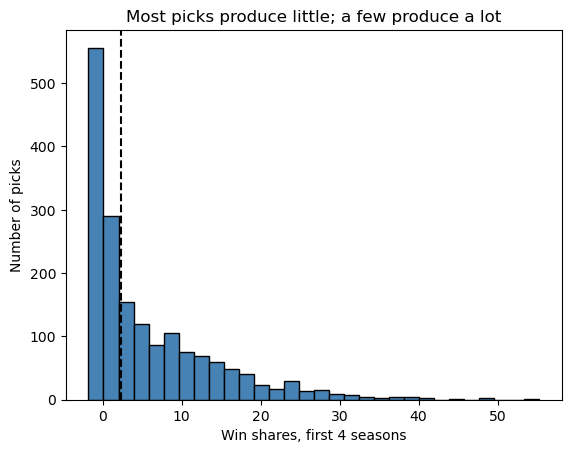

Median: 2.3 | Average: 6.0


In [3]:
players_ws = players["ws_first4"]
value = players["ws_first4"].median()

plt.hist(players_ws, bins=30, color="steelblue", edgecolor="black")
plt.axvline(value, linestyle="--", color="black")
plt.xlabel('Win shares, first 4 seasons')
plt.ylabel('Number of picks')
plt.title('Most picks produce little; a few produce a lot')

plt.show()

print(f"Median: {value:.1f} | Average: {players_ws.mean():.1f}")

## Are the first 4 seasons a good measure of a whole career?

I only measure the first 4 seasons, so I check that this doesn't miss the bigger picture.
Each dot is one player. Players who are good early are almost always good over their career
(correlation = 0.86).

Why not just use career totals? Recent picks haven't finished their careers yet, so it would be
unfair to them. Every player gets the same 4-year window.

Limitation: a few "late bloomers" start slowly and become good later. This measure underrates them.

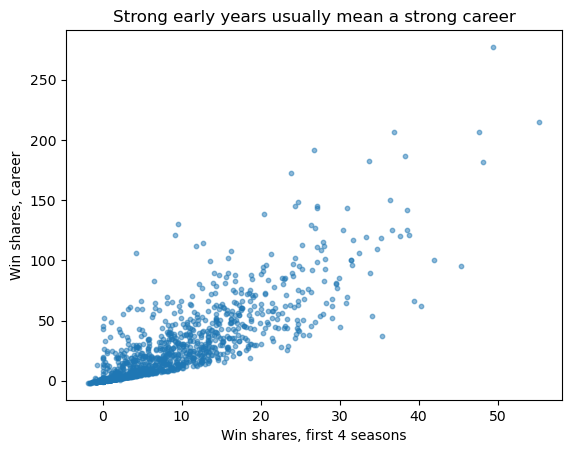

Correlation: 0.86


In [4]:
x = players["ws_first4"]
y = players["ws_career"]

plt.scatter(x, y, s=10, alpha=0.5)
plt.xlabel("Win shares, first 4 seasons")
plt.ylabel("Win shares, career")
plt.title("Strong early years usually mean a strong career")
plt.show()

corr = x.corr(y)
print(f"Correlation: {corr:.2f}")      

## Choosing the "hit" threshold

I check what share of picks would count as a hit at different thresholds.

I chose **10 win shares** (about 2.5 per season, a solid rotation player). About 1 in 4 picks (24%)
reach it. The choice is a judgment call, so later I check whether results change at 8 or 15.

In [5]:
for t in [5, 8, 10, 15, 20]:
    share = (players["ws_first4"] >= t).mean()
    print(f"ws_first4 >= {t}: {share:.0%}")

ws_first4 >= 5: 39%
ws_first4 >= 8: 30%
ws_first4 >= 10: 24%
ws_first4 >= 15: 14%
ws_first4 >= 20: 8%


## Add the `hit` column and save

419 picks are hits and 1,323 are not. "Not a hit" doesn't always mean "bust": it includes
decent bench players who fell just short of the bar.

I save to a **new file** (`draft_players_targets.csv`) instead of overwriting the notebook 01
output, so each step can be rerun without breaking the others.

In [6]:
players["hit"] = players["ws_first4"] >= HIT_THRESHOLD

print("Hits:", players["hit"].sum())
print("Not hits:", (~players["hit"]).sum())

players.to_csv("../data/processed/draft_players_targets.csv", index=False)
print("Saved to draft_players_targets.csv")

Hits: 419
Not hits: 1323
Saved to draft_players_targets.csv
